利用BPTT直接基于iEEG数据的静息态数据来训练deco模型（所有节点的参数互相独立）  
softplus替换回abbottChance激活  
考虑了多种loss、w's LR × 倍数

In [1]:
# setting
GPU_id = '0'
save_path = '/data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/'
save_file = 'training'

# initials
G = 1.0
w = -40.0
I = 0.0

# hyperparameters
epoch_N = 200
lr= 1e-1
optimize_method = 'Adam'
scale_largerLRforW = 1 # scale LR of W
architecture = 'maxNorm' # ['outLinear', 'maxNorm', 'corrLoss'] # outLinear,maxNorm --> MSEloss


In [2]:
# Parameters
GPU_id = "2"
G = 1.0
w = -13.0
I = 0.0
lr = 0.05
scale_largerLRforW = 10
architecture = "maxNorm"
epoch_N = 10000
optimize_method = "Adam"
save_path = "/data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/"
save_file = "G1.0_w-13.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm"


In [3]:
if scale_largerLRforW == 1:
    if_largerLRforW = False
else:
    if_largerLRforW = True
print(if_largerLRforW)

if_have_ITI = True # ITI training style for EC

True


Importing

In [4]:
import matplotlib.pyplot as plt
import numpy as np  
import os,sys,time,jax
from sklearn.utils import gen_batches
# from jax import config
# config.update("jax_debug_nans", True)

import brainpy as bp
import brainpy.math as bm
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"]=GPU_id # specify which GPU(s) to be used
bm.set_platform('gpu')
bm.gpu_memory_preallocation(percent=(1/(2**5))) # bm.disable_gpu_memory_preallocation()
print('bp version:', bp.__version__)

sys.path.append("/data/xyc/codes/iEEG_network/2_data_check_and_loading")
sys.path.append("/data/xyc/codes/iEEG_network/3_analysis_EC")
sys.path.append("/data/xyc/codes/iEEG_network/4_model_BrainPy")
from func_fetch_conn import fetch_conn_ftract,fetch_conn_enigma,fetch_conn_Kong2021
from func_fetch_nodes_variables import fetch_hierarchy_Kong2021,fetch_genes_Kong2021,fetch_genes_enigma
from func_brainpy_model import DecoModel,outLinear,get_AbbottChance
from func_brainpy_metrics import correlation_similarity_flatt,correlation_similarity_batch,cosine_similarity_flatt,cosine_similarity_batch
from func_training import split_dict_by_key,KFold_connectome,get_stim_timing,get_training_data_EC,get_loss_fun_EC,get_train_EC

bp version: 2.4.6.post5


Loading data of connectome

In [5]:
# loading SC
ctx_labels,sc_ctx, fc_ctx = fetch_conn_enigma() # sc is logged, fc is z-transformed
# ctx_labels,sc_ctx, fc_ctx = fetch_conn_Kong2021() # fc is R-value

# loading EC
ctx_labels,ftract_ctx,ftract_ctx_amplitud,ftract_ctx_integral,ftract_ctx_duration = fetch_conn_ftract()

# num of nodes
N = len(ctx_labels)

In [6]:
# SC除以最大值标准化
struc_conn_matrix = sc_ctx / sc_ctx.max()

# # SC基于谱半径标准化
# spec_rad =  np.max(np.abs(np.real(np.linalg.eigvals(struc_conn_matrix))))
# struc_conn_matrix = struc_conn_matrix/spec_rad

# EC 对角元素去掉
ftract_ctx[np.diag_indices_from(ftract_ctx)]=np.nan


N-fold CV of mask training EC: 将EC中的边选出一部分作为test，mask为NaN然后再训练

In [7]:
try:
    print(' #{} in {}-fold'.format(fold_i,fold_N,))
    ftract_ctx=KFold_connectome(ftract_ctx,fold_i,fold_N,)
except:
    print('No CV fold infomation, just pass for training')
    fold_i=None
    fold_N=None

No CV fold infomation, just pass for training


initialization of DecoModel

In [8]:
bm.set_dt(5e-4) # second; 2000Hz sample rate 必须得用这个环境变量设置函数
bm.set_mode(bm.training_mode)

In [9]:
# stack our model to a class
class myModel(bp.DynamicalSystemNS):
    def __init__(self,size, struc_conn_matrix, G, w, I, H_x_act, a):
        super(myModel, self).__init__()
        self.rnnLayer = DecoModel(size=size, struc_conn_matrix=struc_conn_matrix, G=G, w=w, I=I, H_x_act = H_x_act, )
        self.outLayer = outLinear(size=N, a=a)

    def reset_state(self, batch_size=1): # this function defines how to reset the mode states
        self.rnnLayer.reset_state(batch_size)
        
    def update(self, x = 0):
        return self.outLayer(self.rnnLayer(x))

# Instance the class
if architecture == 'outLinear':
    model = myModel(size=N, struc_conn_matrix=bm.asarray(struc_conn_matrix), G=G, w=w, I=I,H_x_act = get_AbbottChance(method = 'custom_jvp'),a = bm.ones(1), )
else:
    model = myModel(size=N, struc_conn_matrix=bm.asarray(struc_conn_matrix), G=G, w=w, I=I,H_x_act = get_AbbottChance(method = 'custom_jvp'),a = None, )

In [10]:
print('Activation Function --> ',  model.rnnLayer.H_x_act.__name__)
sub_dict_list = split_dict_by_key(model.train_vars().unique().dict())
for i in sub_dict_list: display(i)

Activation Function -->  AbbottChance


{'DecoModel0.G': 1.0}

{'DecoModel0.I': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float32)}

{'DecoModel0.w': Array([-13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
        -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
        -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
        -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
        -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
        -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
        -13., -13.], dtype=float32)}

Resting-state warm-up

In [11]:
# inter-trial-interval(iti) resting-state running function
@bm.jit
def run_rest(duration=1.5): # unit of duration is seconds：1.5s是完成刺激trial
    runner = bp.DSRunner(model, progress_bar=False, numpy_mon_after_run=False)
    return runner.run(duration=duration, reset_state=False)

(3000, 68)


(3000, 68)


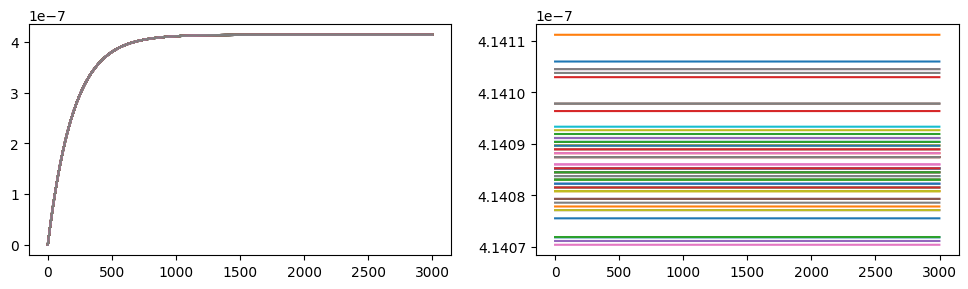

In [12]:
_,(ax1,ax2)=plt.subplots(1,2,figsize=(12,3))

warmup_output = run_rest()[0,:,:]
print(warmup_output.shape)
ax1.plot(warmup_output)

warmup_output = run_rest()[0,:,:]
print(warmup_output.shape)
ax2.plot(warmup_output)
plt.show()

# Training data prepare (based on f-tract)

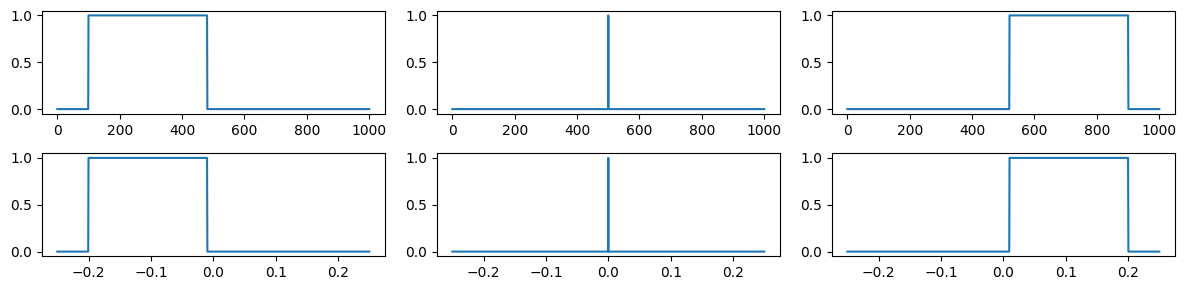

In [13]:
if if_have_ITI:# 前后200ms用于计算loss的时间段作为输入，剩余的静息态由inter-trial-interval来完成，节约计算量
    ts,stim_onset,pre_period,pos_period = get_stim_timing(bm.dt,.25,.25) # 刺激tial为0.5s

else: # 2s秒钟全时间段作为输入
    ts,stim_onset,pre_period,pos_period = get_stim_timing(bm.dt,)

_,axs=plt.subplots(2,3,figsize=(12,3))
axs[0,0].plot(pre_period)
axs[0,1].plot(ts==0)
axs[0,2].plot(pos_period)
axs[1,0].plot(ts,pre_period)
axs[1,1].plot(ts,ts==0)
axs[1,2].plot(ts,pos_period)
plt.tight_layout();plt.show()

In [14]:
tr_EC,tr_stiminput,tr_mask_node,tr_mask_diag,tr_mask_pre,tr_mask_pos,tr_mask_time=get_training_data_EC(
    N, ftract_ctx, (ts,stim_onset,pre_period,pos_period), if_delete_ALLmaskedNodes=False, if_add_epsi_to_zeros=False, epsi=1e-5)

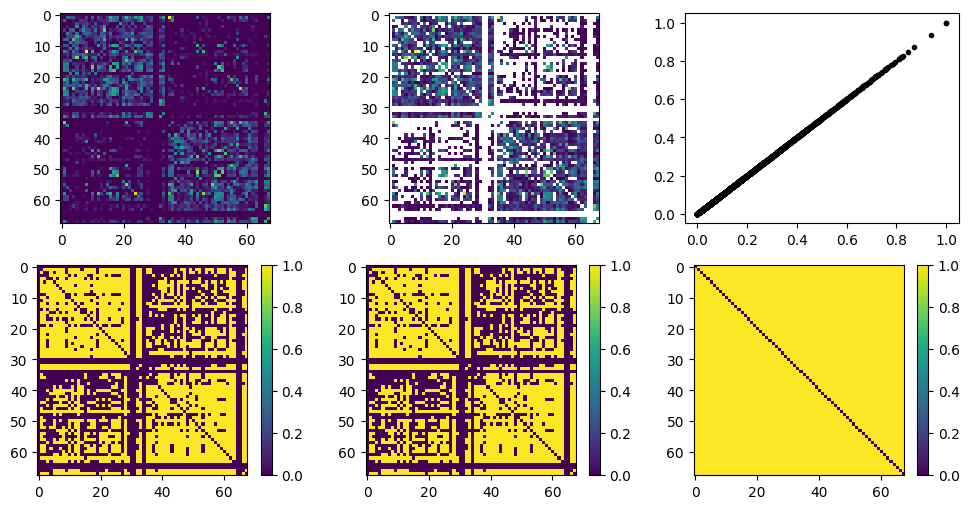

In [15]:
fig,axs=plt.subplots(2,3,figsize=(12,6))
axs[0,0].imshow(tr_EC.T)
axs[0,1].imshow(ftract_ctx)
axs[0,2].plot(tr_EC.T,ftract_ctx,'k.')

img=axs[1,0].imshow(tr_mask_node.mean(axis=1).T)
fig.colorbar(img)

img=axs[1,1].imshow(~np.isnan(ftract_ctx))
fig.colorbar(img)

img=axs[1,2].imshow(tr_mask_diag.mean(axis=1))
fig.colorbar(img)

# Training

prepare

In [16]:
bm.random.seed(123)
np.random.seed(123)

In [17]:
# reset state
model.reset_state(batch_size=tr_stiminput.shape[0])

In [18]:
# move data to GPU
tr_stiminput = bm.asarray(tr_stiminput).cuda()
tr_EC        = bm.asarray(tr_EC).cuda()
tr_mask_time = bm.asarray(tr_mask_time).cuda()
tr_mask_node = bm.asarray(tr_mask_node).cuda()
tr_mask_diag = bm.asarray(tr_mask_diag).cuda()

Loss and training functions

In [19]:
loss_fun_EC = get_loss_fun_EC(model,architecture)
grad_fun_EC,train_EC=get_train_EC(model,loss_fun_EC,optimize_method,lr,if_largerLRforW,scale_largerLRforW)

train_dict: {'DecoModel0.G': TrainVar(value=Array(1.), dtype=float32), 'DecoModel0.I': TrainVar(value=Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                      0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                      0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                      0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float32),
         dtype=float32), 'DecoModel0.w': TrainVar(value=Array([-13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
                      -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
                      -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
                      -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
                      -13., -13., -13., -13., -13., -13., -13., -13., -13., -13., -13.,
                      -13., -13., -13., -13., -13.


opt1: Adam(lr=Constant(lr=0.05, last_epoch=-1), beta1=0.9, beta2=0.999, eps=1e-08)

opt2: Adam(lr=Constant(lr=0.5, last_epoch=-1), beta1=0.9, beta2=0.999, eps=1e-08)


Strat training:

In [20]:
%%time

epoch_ECloss=np.zeros((epoch_N,))

epoch_G=np.zeros((epoch_N,))
epoch_a=np.zeros((epoch_N,))
epoch_w=np.zeros((epoch_N,N))
epoch_I=np.zeros((epoch_N,N))

epoch_grad_G=np.zeros((epoch_N,))
epoch_grad_a=np.zeros((epoch_N,))
epoch_grad_w=np.zeros((epoch_N,N))
epoch_grad_I=np.zeros((epoch_N,N))

for epoch_i in range(epoch_N): # epoch level

    # get mini-batch
    ids = np.arange(tr_stiminput.shape[0])
    np.random.shuffle(ids)

    # inter-trial-interval(iti) resting-state running function
    if if_have_ITI: run_rest()

    # full-batch training
    grads, ECloss = train_EC(tr_stiminput[ids,:,:], tr_EC[ids,:], (tr_mask_time[ids,:,:], tr_mask_node[ids,:,:], tr_mask_diag[ids,:,:]) )

    # appending results
    epoch_ECloss[epoch_i]=ECloss

    epoch_G[epoch_i]=np.asarray(model.rnnLayer.G)
    epoch_w[epoch_i,:]=np.asarray(model.rnnLayer.w)
    epoch_I[epoch_i,:]=np.asarray(model.rnnLayer.I)
    epoch_a[epoch_i]=np.asarray(model.outLayer.a)
    
    epoch_grad_G[epoch_i]=np.asarray(grads['DecoModel0.G'])
    epoch_grad_w[epoch_i,:]=np.asarray(grads['DecoModel0.w'])
    epoch_grad_I[epoch_i,:]=np.asarray(grads['DecoModel0.I'])
    try: epoch_grad_a[epoch_i]=np.asarray(grads['outLinear0.a'])
    except: pass

    # print
    if epoch_i<20 or epoch_i%100==0 :
        print(
            epoch_i, 
            '| Loss=',epoch_ECloss[epoch_i],
            "| G=",epoch_G[epoch_i],"Grad(G)=",bm.abs(grads['DecoModel0.G']).max(),
            '| w=',epoch_w[epoch_i,:].mean(),"Grad(w)=",bm.abs(grads['DecoModel0.w']).max(),
            "| I=",epoch_I[epoch_i,:].mean(),"Grad(I)=",bm.abs(grads['DecoModel0.I']).max(),
            "| a=",epoch_a[epoch_i],"Grad(a)=",bm.abs(epoch_grad_a[epoch_i]).max(),
        )

0 | Loss= 0.020886942744255066 | G= 0.9500002861022949 Grad(G)= 0.010857482 | w= -12.958678610184613 Grad(w)= 1.9526948e-05 | I= 0.03882626913871397 Grad(I)= 0.18526429 | a= 1.0 Grad(a)= 0.0
1 | Loss= 0.018164779990911484 | G= 0.8881102204322815 Grad(G)= 0.0050379047 | w= -12.985609952141257 Grad(w)= 2.0867046e-06 | I= 0.05701119606109226 Grad(I)= 0.011743204 | a= 1.0 Grad(a)= 0.0


2 | Loss= 0.018814194947481155 | G= 0.8316916823387146 Grad(G)= 0.000166237 | w= -13.11420207865098 Grad(w)= 2.9933435e-05 | I= 0.06936270179336562 Grad(I)= 0.039586816 | a= 1.0 Grad(a)= 0.0
3 | Loss= 0.020442118868231773 | G= 0.8063347935676575 Grad(G)= 0.005477203 | w= -13.268017965204576 Grad(w)= 3.3012097e-05 | I= 0.08321536728180945 Grad(I)= 0.009259705 | a= 1.0 Grad(a)= 0.0


4 | Loss= 0.020046347752213478 | G= 0.7950006723403931 Grad(G)= 0.0029482637 | w= -13.417097905102898 Grad(w)= 0.00017157153 | I= 0.09644132055451765 Grad(I)= 0.016650379 | a= 1.0 Grad(a)= 0.0
5 | Loss= 0.01940660923719406 | G= 0.7882302403450012 Grad(G)= 0.00092068024 | w= -13.626848837908577 Grad(w)= 0.00044123566 | I= 0.10801566249745734 Grad(I)= 0.010143077 | a= 1.0 Grad(a)= 0.0


6 | Loss= 0.019034037366509438 | G= 0.7850146889686584 Grad(G)= 0.00077565014 | w= -13.885415203431073 Grad(w)= 0.00066806376 | I= 0.11756339255610809 Grad(I)= 0.005861231 | a= 1.0 Grad(a)= 0.0
7 | Loss= 0.018260518088936806 | G= 0.7881978154182434 Grad(G)= 0.0016478583 | w= -14.147765538271736 Grad(w)= 0.00065166276 | I= 0.12532825510510626 Grad(I)= 0.0057978453 | a= 1.0 Grad(a)= 0.0


8 | Loss= 0.017198018729686737 | G= 0.7933905124664307 Grad(G)= 0.0006341324 | w= -14.395198008593391 Grad(w)= 0.00045421533 | I= 0.13117043001522474 Grad(I)= 0.0042872983 | a= 1.0 Grad(a)= 0.0
9 | Loss= 0.016656573861837387 | G= 0.7996904253959656 Grad(G)= 0.0004427931 | w= -14.634138345718384 Grad(w)= 0.00019623105 | I= 0.13617550110553994 Grad(I)= 0.0031238832 | a= 1.0 Grad(a)= 0.0


10 | Loss= 0.016521213576197624 | G= 0.809589147567749 Grad(G)= 0.0011595696 | w= -14.835440306102528 Grad(w)= 7.256806e-05 | I= 0.14168404464555137 Grad(I)= 0.0025031155 | a= 1.0 Grad(a)= 0.0
11 | Loss= 0.016573481261730194 | G= 0.8240137696266174 Grad(G)= 0.0015288307 | w= -14.979037719614366 Grad(w)= 0.0002810007 | I= 0.14822834730148315 Grad(I)= 0.0021149043 | a= 1.0 Grad(a)= 0.0


... (100 outputs left out)

9700 | Loss= 0.007369937375187874 | G= 0.9351767301559448 Grad(G)= 0.0005714422 | w= -15.779799927683438 Grad(w)= 1.6894855e-05 | I= 0.9913910512319383 Grad(I)= 0.00021215226 | a= 1.0 Grad(a)= 0.0


9800 | Loss= 0.007353413384407759 | G= 0.9347763061523438 Grad(G)= 0.000264198 | w= -15.728836760801428 Grad(w)= 7.793359e-06 | I= 0.9974783365340794 Grad(I)= 0.00025070304 | a= 1.0 Grad(a)= 0.0


9900 | Loss= 0.007361192721873522 | G= 0.9360597133636475 Grad(G)= 0.0005988944 | w= -15.74512670320623 Grad(w)= 3.197997e-05 | I= 0.9900887496221591 Grad(I)= 0.00036672494 | a= 1.0 Grad(a)= 0.0


CPU times: user 15min 29s, sys: 5min 6s, total: 20min 35s
Wall time: 21min 44s


# Plot and save

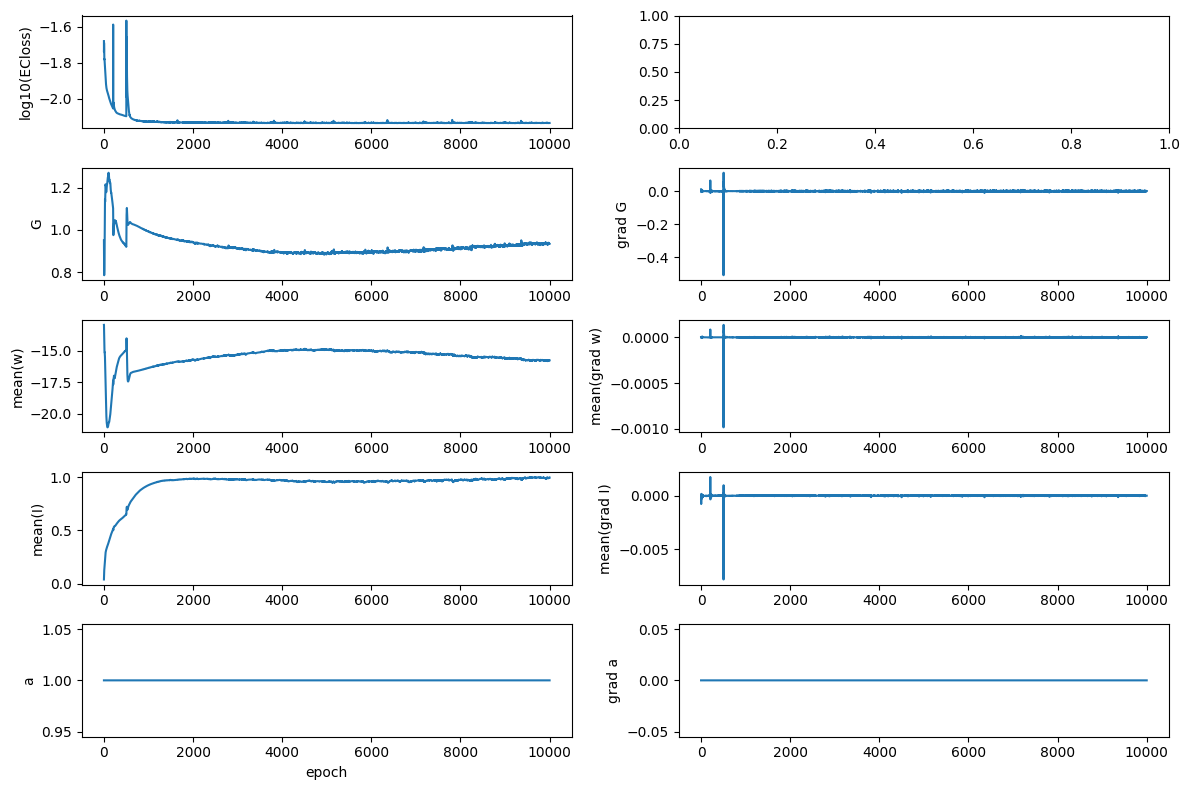

In [21]:
_,axs = plt.subplots(5,2,figsize=(12,8))

axs[0,0].plot(np.log10(epoch_ECloss))
axs[0,0].set_ylabel("log10(ECloss)")


axs[1,0].plot(epoch_G)
axs[1,0].set_ylabel("G")

axs[2,0].plot(np.mean(epoch_w,axis=1))
axs[2,0].set_ylabel("mean(w)")

axs[3,0].plot(np.mean(epoch_I,axis=1))
axs[3,0].set_ylabel("mean(I)")

axs[4,0].plot(epoch_a)
axs[4,0].set_ylabel("a")
axs[4,0].set_xlabel("epoch")

axs[1,1].plot(epoch_grad_G)
axs[1,1].set_ylabel("grad G")

axs[2,1].plot(np.mean(epoch_grad_w,axis=1))
axs[2,1].set_ylabel("mean(grad w)")

axs[3,1].plot(np.mean(epoch_grad_I,axis=1))
axs[3,1].set_ylabel("mean(grad I)")

axs[4,1].plot(epoch_grad_a)
axs[4,1].set_ylabel("grad a")

plt.tight_layout()
plt.show()

In [22]:
display(model.train_vars())

{'DecoModel0.G': TrainVar(value=Array(0.9337772), dtype=float32),
 'DecoModel0.I': TrainVar(value=Array([ 0.40447006,  0.2582114 ,  0.7689504 ,  1.8458899 ,  0.4788377 ,
                        0.6437866 ,  1.3660218 ,  1.2455229 ,  0.41689244,  1.9579556 ,
                        0.68331414,  2.8941298 ,  0.50096214,  2.1647708 ,  0.20929073,
                        1.0337957 ,  0.28939334,  0.1623374 ,  0.30959782,  1.3627181 ,
                        0.55284995,  0.03857949,  1.1895188 ,  1.224672  ,  0.53513014,
                        1.5295292 ,  2.1515877 ,  3.8469882 ,  2.2942038 ,  0.81483346,
                        1.8485768 , -0.26595435,  0.29424903,  1.4263178 ,  0.37143221,
                        0.27194905,  0.83414567,  0.24269454,  0.4893761 ,  0.420812  ,
                        2.1936457 ,  0.84770316,  1.8003582 ,  1.4987317 ,  0.56336254,
                        1.5712438 ,  0.66185164,  1.7408881 ,  0.28379774,  0.80860025,
                        0.18782285,  0

In [23]:
# save
states = {
#初值：
'G': G, 
'w': w,
'I': I,
#超参：
'epoch_N':epoch_N,
'lr':lr,
'optimize_method':optimize_method,
'scale_largerLRforW':scale_largerLRforW, # scale LR of W
'architecture':architecture, # ['outLinear', 'maxNorm', 'corrLoss'] # outLinear,maxNorm --> MSEloss
'if_have_ITI':if_have_ITI,
#fold相关：
'fold_i':fold_i,
'fold_N':fold_N,
#训练结果：
'model':model.state_dict(), 
#训练过程：
'epoch_ECloss':epoch_ECloss, 
'epoch_G':epoch_G,
'epoch_w':epoch_w,
'epoch_I':epoch_I,
'epoch_a':epoch_a,
'epoch_grad_G':epoch_grad_G,
'epoch_grad_w':epoch_grad_w,
'epoch_grad_I':epoch_grad_I,
'epoch_grad_a':epoch_grad_a,
}
bp.checkpoints.save_pytree(save_path+save_file+'.bp', states) 

Saving checkpoint into /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract/training/G1.0_w-13.0_I0.0_Adam_lr0.05_wLRx10_epo10k_maxNorm.bp
